In [6]:
#Load the dataset
import pandas as pd

df = pd.read_csv("dataset.csv")
print(f"Original dataset rows: {df.shape[0]:,}")
print(f"Original dataset columns: {df.shape[1]}")
print("Column names:")
print(df.columns.tolist())

Original dataset rows: 1,500,000
Original dataset columns: 39
Column names:
['ticket_id', 'created_at', 'issue_description', 'category', 'issue_type_id', 'product', 'channel', 'region', 'language', 'customer_name', 'customer_email', 'customer_age', 'customer_gender', 'subscription_type', 'customer_tenure_months', 'previous_tickets', 'customer_segment', 'priority', 'issue_complexity_score', 'assigned_team', 'assigned_to', 'status', 'auto_resolved', 'escalated_to_human', 'escalation_reason', 'reopen_count', 'first_response_time_hours', 'resolution_time_hours', 'paused_hours', 'resolution_wallclock_hours', 'first_resolved_at', 'resolved_at', 'closed_at', 'resolved_by', 'resolution_notes', 'sla_target_hours', 'sla_breached', 'sla_breach_margin', 'customer_satisfaction_score']


In [7]:
#Feature Selection
keep_columns = [
    "ticket_id",
    "issue_description",
    "category",
    "resolution_notes",
]
df = df[keep_columns]
print("Columns kept:", df.columns.tolist())

Columns kept: ['ticket_id', 'issue_description', 'category', 'resolution_notes']


In [8]:
#Data Cleaning
df.drop_duplicates(inplace=True)
print(df.isnull().sum())
df.dropna(inplace=True)
print(df.isnull().sum())
print(len(df))

C:\Users\ISHVARYA KALYANKUMAR\AppData\Local\Temp\ipykernel_35420\1581803634.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


ticket_id                0
issue_description        0
category                 0
resolution_notes     96402
dtype: int64
ticket_id            0
issue_description    0
category             0
resolution_notes     0
dtype: int64
1403598


C:\Users\ISHVARYA KALYANKUMAR\AppData\Local\Temp\ipykernel_35420\1581803634.py:4: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


In [9]:
#Data Splitting
train_df = df.sample(frac=0.995, random_state=42)
test_df = df.drop(train_df.index)
train_df.to_csv("train.csv", index=False)
test_df.to_csv("test.csv", index=False)
print(f"Train rows: {len(train_df):,}")
print(f"Test rows: {len(test_df):,}")


Train rows: 1,396,580
Test rows: 7,018


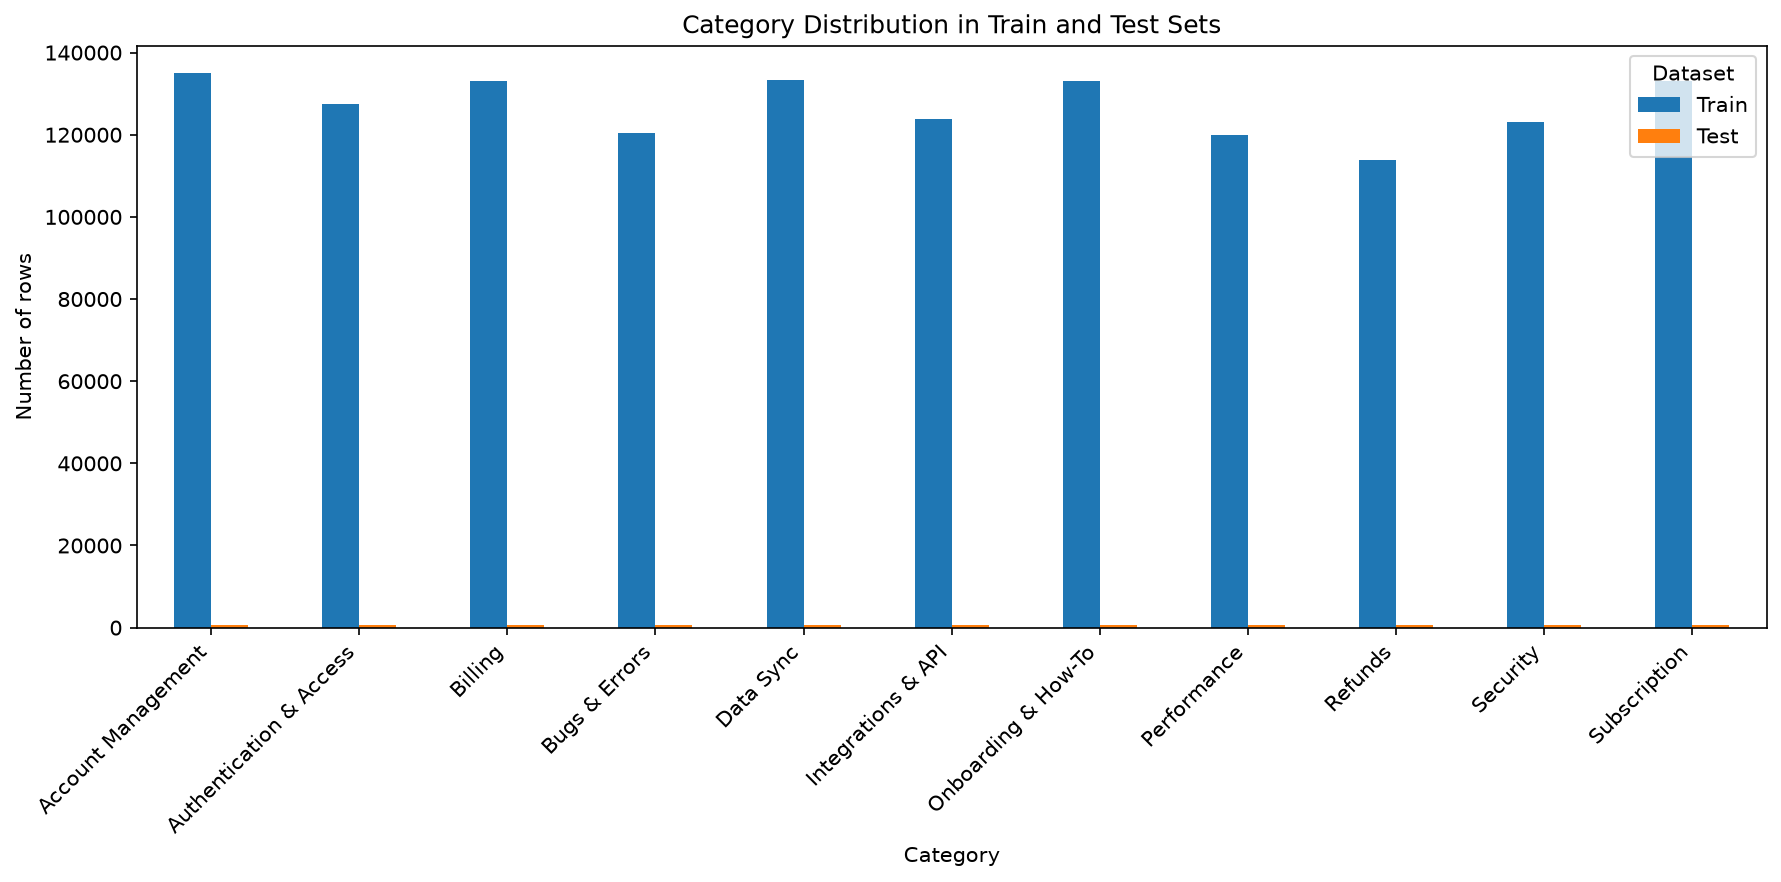

In [10]:
#Data Visualization for Category Distribution
import os
os.environ["MPLBACKEND"] = "Agg"

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

category_distribution = pd.DataFrame({
    "Train": train_df["category"].value_counts(),
    "Test": test_df["category"].value_counts(),
}).fillna(0).sort_index()

ax = category_distribution.plot(kind="bar", figsize=(12, 6))
ax.set_title("Category Distribution in Train and Test Sets")
ax.set_xlabel("Category")
ax.set_ylabel("Number of rows")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Dataset")
plt.tight_layout()
chart_path = "category_distribution.png"
plt.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.close()
display(Image(filename=chart_path))